In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


In [2]:
#Wrote - flux values as 0 
v5589 = pd.read_csv('v5589sgr_edit.dat', delim_whitespace = True, header = 0)

v5589_opt = pd.read_csv('v5589sgr_aavso.dat', header = 0)


/var/folders/xv/dvsld6lx4xs_nbgh_qcl11d00000gn/T/ipykernel_67864/809208789.py:2: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  v5589 = pd.read_csv('v5589sgr_edit.dat', delim_whitespace = True, header = 0)


In [3]:
#go from JD to days since eruption 
#sort out and only use the v band 


band = v5589_opt['Band']
JD = v5589_opt['JD']
opt_mag = v5589_opt['Magnitude']
opt_err = v5589_opt['Uncertainty']


def sort_band(B,J,M,E):
    new_band = []
    new_mag = []
    new_err = []
    new_JD = []
    
    for i in range(len(B)):
        if B[i]=='V':
            new_band.append(B[i])
            new_JD.append(float(J[i]))
            new_mag.append(float(M[i]))
            new_err.append(float(E[i]))
            
    return(new_band,new_JD, new_mag, new_err)

V_band = sort_band(band, JD, opt_mag, opt_err)


In [4]:
#April 21, 2012
#MJD 56038.0 (t_0)  
#JD 2456038.5000000 (t_0)


def JD_to_date(jul):
    days = []
    for i in range(len(jul)):
        days.append(float(jul[i])-2456038.5000000)
    return(days)


days_opt = JD_to_date(V_band[1])

In [5]:
#v5589
#days = v5589['Day']
freq = v5589['Freq']
flux = v5589['Flux']
ferr = v5589['eFlux']
v5589_ep = v5589['#Epoch']
mjd = v5589['MJd']

In [6]:
#Day of Outburst is April 21, 2012: 56038.0 in MJD 

def MJD_to_date(MJD, first):
    days = []
    for i in range(len(MJD)):
        days.append(float(MJD[i]) - first)
    return(days)

days = np.array(MJD_to_date(mjd,56038.0))

In [7]:
#Logical conditions: frequency range 
A = np.logical_and(freq>= 0, freq<= 1.5)
B = np.logical_and(freq>= 1.5, freq<= 2)
C = np.logical_and(freq>= 3, freq<= 6)
D = np.logical_and(freq>= 6.1, freq<= 8)
E = np.logical_and(freq>= 10, freq<= 14)
F = np.logical_and(freq>= 15, freq<= 20)
G = np.logical_and(freq>= 21, freq<= 30)
H = np.logical_and(freq>= 31, freq<= 40)

In [8]:
#Obtain indices using 'where' sorting by frequency 

L_AC =  np.where(np.logical_and(A, flux > 3*ferr))   #L band AC
L_nac = np.where(np.logical_and(A, flux < 3*ferr))   #L band AC non detection 

L_BD =  np.where(np.logical_and(B, flux > 3*ferr))   #L band BD
L_nbd = np.where(np.logical_and(B, flux < 3*ferr))   #L band BD non detection


C_AC =  np.where(np.logical_and(C, flux > 3*ferr))   #C band AC
C_nac = np.where(np.logical_and(C, flux < 3*ferr))   #C band AC non detection

C_BD =  np.where(np.logical_and(D, flux > 3*ferr))   #C band AC
C_nbd = np.where(np.logical_and(D, flux < 3*ferr))   #C band AC non detection

Ku_AC =  np.where(np.logical_and(E, flux > 3*ferr))  #Ku band AC
Ku_nac = np.where(np.logical_and(E, flux < 3*ferr))  #Ku band AC non detection 

Ku_BD =  np.where(np.logical_and(F, flux > 3*ferr))  #Ku band BD
Ku_nbd = np.where(np.logical_and(F, flux < 3*ferr))  #Ku band BD non detection 

Ka_AC =  np.where(np.logical_and(G, flux > 3*ferr))  #Ka band AC
Ka_nac = np.where(np.logical_and(G, flux < 3*ferr))  #Ka band AC non detection

Ka_BD =  np.where(np.logical_and(H, flux > 3*ferr))  #Ka band BD
Ka_nbd = np.where(np.logical_and(H, flux < 3*ferr))  #Ka band BD non detection 

In [9]:
freq_LAC = np.ravel([freq[i] for i in L_AC])
flux_LAC = np.ravel([flux[i] for i in L_AC])
err_LAC  = np.ravel([ferr[i] for i in L_AC])
date_LAC = np.ravel([days[i] for i in L_AC])

nflux_LAC = np.ravel([flux[i] + ferr[i]*3 for i in L_nac])
ndate_LAC = np.ravel([days[i] for i in L_nac])
####################################################

freq_LBD = np.ravel([freq[i] for i in L_BD])
flux_LBD = np.ravel([flux[i] for i in L_BD])
err_LBD  = np.ravel([ferr[i] for i in L_BD])
date_LBD = np.ravel([days[i] for i in L_BD])

nflux_LBD = np.ravel([flux[i] +ferr[i]*3 for i in L_nbd])
ndate_LBD = np.ravel([days[i] for i in L_nbd])
####################################################

freq_CAC = np.ravel([freq[i] for i in C_AC])
flux_CAC = np.ravel([flux[i] for i in C_AC])
err_CAC  = np.ravel([ferr[i] for i in C_AC])
date_CAC = np.ravel([days[i] for i in C_AC])

nflux_CAC = np.ravel([flux[i] +ferr[i]*3 for i in C_nac])
ndate_CAC = np.ravel([days[i] for i in C_nac])
#####################################################


freq_CBD = np.ravel([freq[i] for i in C_BD])
flux_CBD = np.ravel([flux[i] for i in C_BD])
err_CBD  = np.ravel([ferr[i] for i in C_BD])
date_CBD = np.ravel([days[i] for i in C_BD])

nflux_CBD = np.ravel([flux[i] +ferr[i]*3 for i in C_nbd])
ndate_CBD = np.ravel([days[i] for i in C_nbd])
#####################################################
freq_KuAC = np.ravel([freq[i] for i in Ku_AC])
flux_KuAC = np.ravel([flux[i] for i in Ku_AC])
err_KuAC  = np.ravel([ferr[i] for i in Ku_AC])
date_KuAC = np.ravel([days[i] for i in Ku_AC])

nflux_KuAC = np.ravel([flux[i] +ferr[i]*3 for i in Ku_nac])
ndate_KuAC = np.ravel([days[i] for i in Ku_nac])
#####################################################

freq_KuBD = np.ravel([freq[i] for i in Ku_BD])
flux_KuBD = np.ravel([flux[i] for i in Ku_BD])
err_KuBD  = np.ravel([ferr[i] for i in Ku_BD])
date_KuBD = np.ravel([days[i] for i in Ku_BD])

nflux_KuBD = np.ravel([flux[i] +ferr[i]*3 for i in Ku_nbd])
ndate_KuBD = np.ravel([days[i] for i in Ku_nbd])

#####################################################
freq_KaAC = np.ravel([freq[i] for i in Ka_AC])
flux_KaAC = np.ravel([flux[i] for i in Ka_AC])
err_KaAC  = np.ravel([ferr[i] for i in Ka_AC])
date_KaAC = np.ravel([days[i] for i in Ka_AC])

nflux_KaAC = np.ravel([flux[i] +ferr[i]*3 for i in Ka_nac])
ndate_KaAC = np.ravel([days[i] for i in Ka_nac])
#####################################################

freq_KaBD = np.ravel([freq[i] for i in Ka_BD])
flux_KaBD = np.ravel([flux[i] for i in Ka_BD])
err_KaBD  = np.ravel([ferr[i] for i in Ka_BD])
date_KaBD = np.ravel([days[i] for i in Ka_BD])

nflux_KaBD = np.ravel([flux[i] +ferr[i]*3 for i in Ka_nbd])
ndate_KaBD = np.ravel([days[i] for i in Ka_nbd])



In [10]:
def quad(err,freq,flux):
    quad_er = []

    for i in range(len(freq)):
        if freq[i] < 10.0:
            p1 = np.sqrt(err[i]**2 + (flux[i]*0.05)**2)
            quad_er.append(p1)
        
        else: 
            p2 = np.sqrt(err[i]**2 + (flux[i]*0.10)**2)
            quad_er.append(p2)
            
        
    return(quad_er)  

In [11]:
quad_Lac = quad(err_LAC,freq_LAC, flux_LAC)    
quad_Lbd = quad(err_LBD,freq_LBD, flux_LBD)    
quad_Cac = quad(err_CAC,freq_CAC, flux_CAC) 
quad_Cbd = quad(err_CBD,freq_CBD, flux_CBD) 
quad_Kuac = quad(err_KuAC,freq_KuAC, flux_KuAC) 
quad_Kubd = quad(err_KuBD,freq_KuBD, flux_KuBD) 
quad_Kaac = quad(err_KaAC,freq_KaAC, flux_KaAC) 
quad_Kabd = quad(err_KaBD,freq_KaBD, flux_KaBD) 

In [12]:
alpha = [0.77,0.56,0.15,0.20, -0.14, 0.12,-0.14, -0.09, -0.91, -0.40]
alpha_err = [0.25, 0.09, 0.01, 0.13, 0.39, 0.08, 0.04, 0.13, 0.31, 0.31]
alpha_day = [46.4,54.2,62.3,81.1,90.3,110.0,113.3,129,136.2,139.9]

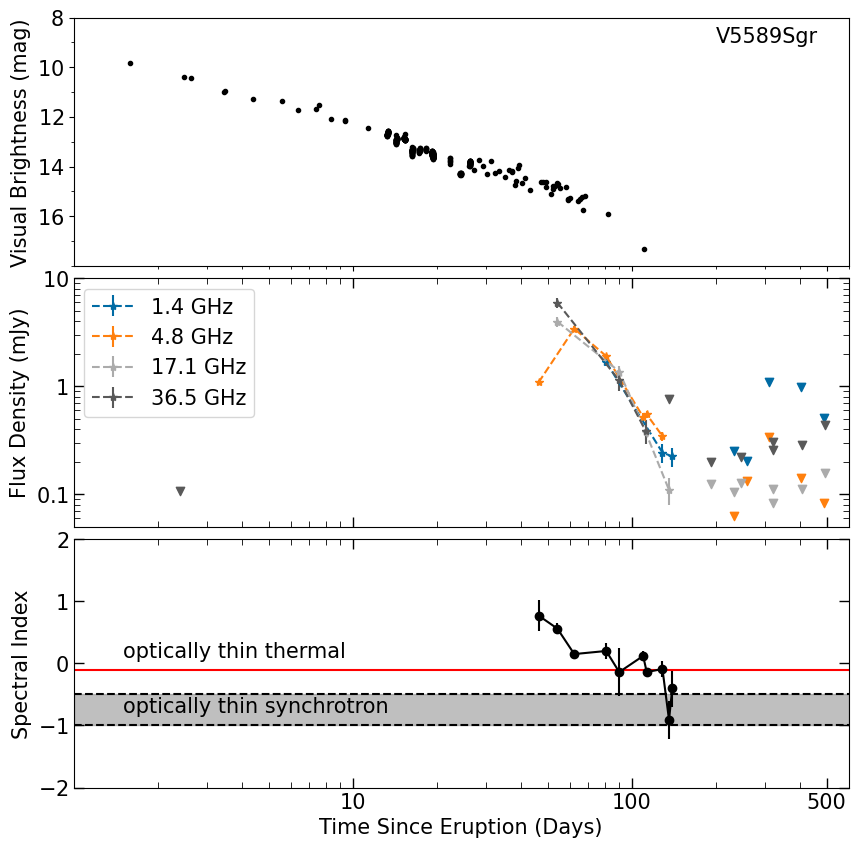

In [18]:
plt.style.use('tableau-colorblind10')

from matplotlib.ticker import AutoMinorLocator

fig, axs = plt.subplots(3, 1, figsize=(10, 10), sharey=False, sharex = True)#, constrained_layout=True)


axs[0].scatter(days_opt, V_band[2], marker = '.', color = 'black')
axs[0].annotate('V5589Sgr',(200,9), fontsize=15)
axs[0].set_xscale('log')
axs[0].set_ylabel('Visual Brightness (mag)',fontsize =15)

axs[0].set_yticks([8,10,12,14,16], labels = [r'$8$',r'$10$', r'$12$', r'$14$',r'$16$'], fontsize = 15)
axs[0].set_ylim(8,18)
axs[0].invert_yaxis()
axs[0].yaxis.set_minor_locator(AutoMinorLocator(2))  # 2 minor intervals between major ticks


axs[1].set_ylabel('Flux Density (mJy)',fontsize=15)
axs[1].set_xscale('log')
axs[1].set_yscale('log')

axs[1].errorbar(date_LAC, flux_LAC, yerr=quad_Lac, linestyle ='--', fmt = '*',label='1.4 GHz')
axs[1].errorbar(date_CAC, flux_CAC, yerr=quad_Cac, linestyle = '--', fmt = '*',label='4.8 GHz')
#axs[1].errorbar(date_CBD, flux_CBD, yerr=quad_Cbd, linestyle = '--', fmt = '*',label='7.0 Ghz')
axs[1].errorbar(date_KuBD, flux_KuBD, yerr=quad_Kubd, linestyle = '--', fmt = '*',label='17.1 GHz')
axs[1].errorbar(date_KaBD, flux_KaBD, yerr=quad_Kabd, linestyle = '--', fmt = '*',label='36.5 GHz')


axs[1].scatter(ndate_LAC, nflux_LBD, marker = 'v')
axs[1].scatter(ndate_CAC, nflux_CAC, marker = 'v')
#axs[1].scatter(ndate_CBD, nflux_CBD, marker= 'v')
axs[1].scatter(ndate_KuBD, nflux_KuBD, marker= 'v')
axs[1].scatter(ndate_KaBD, nflux_KaBD, marker= 'v')
axs[1].legend(fontsize=15, loc='upper left')
axs[1].set_yticks([0.1,1,10], labels = [r'$0.1$',r'$1$',r'$10$'], fontsize = 15)
axs[1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[1].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)


########### Panel 3 ############

axs[2].errorbar(alpha_day, alpha, yerr=alpha_err, marker = 'o', color = 'black')
axs[2].axhline(y = -0.1, color = 'red', linestyle = '-')
axs[2].axhline(y = -0.5, color = 'black', linestyle = '--')
axs[2].axhline(y = -1, color = 'black', linestyle = '--')
axs[2].fill_between(x=[1,600],y1=-0.5,y2=-1, color = 'grey', alpha=.5)

axs[2].set_xlabel('Time Since Eruption (Days)', fontsize=15)
axs[2].set_ylabel('Spectral Index', fontsize=15)
axs[2].annotate('optically thin thermal', (1.5,0.1), fontsize=15)
axs[2].annotate('optically thin synchrotron', (1.5,-0.8), fontsize=15)

axs[2].set_xticks([10,100,500], labels = ['10','100','500'], fontsize = 15)
axs[2].set_yticks([-2,-1,0,1,2], labels = [r'$-2$',r'$-1$',r'$0$',r'$1$',r'$2$'], fontsize = 15)
axs[2].set_ylim(-2,2)
axs[2].set_xlim(1,600)

axs[2].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[2].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)


fig.subplots_adjust(hspace=0.05)
plt.savefig("V5589Sgr_RadioOptical_lightcurves.png")
plt.show();